In [62]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import seaborn as sns

# Data colection

## Sélection des actifs

In [60]:
print ("================= Welcome to the Portfolio Risk Engine!=====================")
print ()
print ("Please enter the tickers of your portfolio assets (separated by commas):")
tickers = []
for i in range(6):
    ticker = input(f'Enter the {i+1} asset ticker: ')
    tickers.append(ticker)

print (f"You have entered the following tickers: {tickers}")

================= Welcome to the Portfolio Risk Engine!=====================

Please enter the tickers of your portfolio assets (separated by commas):
You have entered the following tickers: ['aapl', 'nee', 'pg', 'jpm', 'amzn', 'cat']


In [61]:
#tickers = [actif1, actif2, actif3, actif4, actif5, actif6]
test = yf.download(tickers, start="2020-01-01", end="2023-01-01")['Close']
test = test.dropna(axis=1, how='all')  # Drop columns with all NaN values
print (test)

[*********************100%***********************]  6 of 6 completed

Ticker            AAPL       AMZN         CAT         JPM        NEE  \
Date                                                                   
2020-01-02   72.271530  94.900497  132.067856  117.313957  50.335979   
2020-01-03   71.568901  93.748497  130.234207  115.765846  50.694595   
2020-01-06   72.139191  95.143997  130.146454  115.673759  50.947739   
2020-01-07   71.799927  95.343002  128.426865  113.707245  50.903431   
2020-01-08   72.954910  94.598503  129.567383  114.594261  50.880234   
...                ...        ...         ...         ...        ...   
2022-12-23  129.547653  85.250000  226.521530  119.621933  75.489136   
2022-12-27  127.749756  83.040001  229.609543  120.041107  75.336662   
2022-12-28  123.829727  81.820000  226.058807  120.697174  74.583298   
2022-12-29  127.337135  84.180000  226.833206  121.389679  75.408409   
2022-12-30  127.651520  84.000000  226.228760  122.191544  74.977921   

Ticker              PG  
Date                    
2020-01-02  1

In [5]:
tickers = ('AAPL', 'JPM','JNJ','AMZN','PG','NEE','CAT','AMT','GLD')
data = yf.download (tickers, start='2020-01-01', end='2025-12-31')['Close']
data = pd.DataFrame(data).dropna()
data

[*********************100%***********************]  9 of 9 completed


Ticker,AAPL,AMT,AMZN,CAT,GLD,JNJ,JPM,NEE,PG
Date,,,,,,,,,
2020-01-02,72.271530,187.878418,94.900497,132.067841,143.949997,121.338509,117.313950,50.335987,103.959305
2020-01-03,71.568916,187.968872,93.748497,130.234192,145.860001,119.933678,115.765831,50.694595,103.260117
2020-01-06,72.139191,187.919525,95.143997,130.146484,147.389999,119.784111,115.673775,50.947731,103.403336
2020-01-07,71.799934,183.915253,95.343002,128.426880,147.970001,120.515572,113.707214,50.903431,102.763107
2020-01-08,72.954918,185.510391,94.598503,129.567413,146.860001,120.498955,114.594246,50.880215,103.201141
...,...,...,...,...,...,...,...,...,...
2025-12-23,271.620667,167.687561,232.139999,578.882446,413.640015,202.522552,319.771271,78.086189,140.062469
2025-12-24,273.066711,167.966232,232.380005,580.214355,411.929993,204.490875,322.950073,78.732086,141.343964
2025-12-26,272.657837,169.513290,232.520004,579.458984,416.739990,204.343246,321.713837,78.692955,141.588501


# Poids des actifs

In [ ]:
weights = []
for ticker in tickers : 
    weight = float(input(f'Enter the weight of {ticker}: '))
    weights.append(weight)
    print (f"You have entered the following weight for {ticker}: {weight}")
    print (f"Current weights: {weights}")

if sum(weights) != 1:
    print("Error: The sum of the weights must be equal to 1.")

You have entered the following weight for aapl: 0.2
Current weights: [0.2]
You have entered the following weight for nee: 0.1
Current weights: [0.2, 0.1]
You have entered the following weight for pg: 0.1
Current weights: [0.2, 0.1, 0.1]
You have entered the following weight for jpm: 0.3
Current weights: [0.2, 0.1, 0.1, 0.3]
You have entered the following weight for amzn: 0.15
Current weights: [0.2, 0.1, 0.1, 0.3, 0.15]
You have entered the following weight for cat: 0.15
Current weights: [0.2, 0.1, 0.1, 0.3, 0.15, 0.15]


# Analytics & models

## Calcul du rendement du portefeuille

In [ ]:
data_returns = data.pct_change().dropna() #rendements journaliers
assets_returns = data_returns.mean (axis=0) #moyennes des rendements par actifs
print (assets_returns)


Ticker
AAPL    0.001081
AMT     0.000114
AMZN    0.000848
CAT     0.001184
GLD     0.000730
JNJ     0.000420
JPM     0.000856
NEE     0.000477
PG      0.000286
dtype: float64


In [7]:
portfolio_weights = np.array([0.15, 0.1, 0.2, 0.1, 0.2, 0.1, 0.05, 0.05, 0.05])  # Example weights for the assets
portfolio = pd.DataFrame ({'Assets': data.columns, 'Returns': assets_returns, 'Weights': portfolio_weights})

In [8]:
portfolio_returns = portfolio['Returns']*portfolio['Weights']
print(f"Expected Portfolio Return: {portfolio_returns.sum():.4f}")

Expected Portfolio Return: 0.0007


## Correlation heatmap

<Axes: xlabel='Ticker', ylabel='Ticker'>

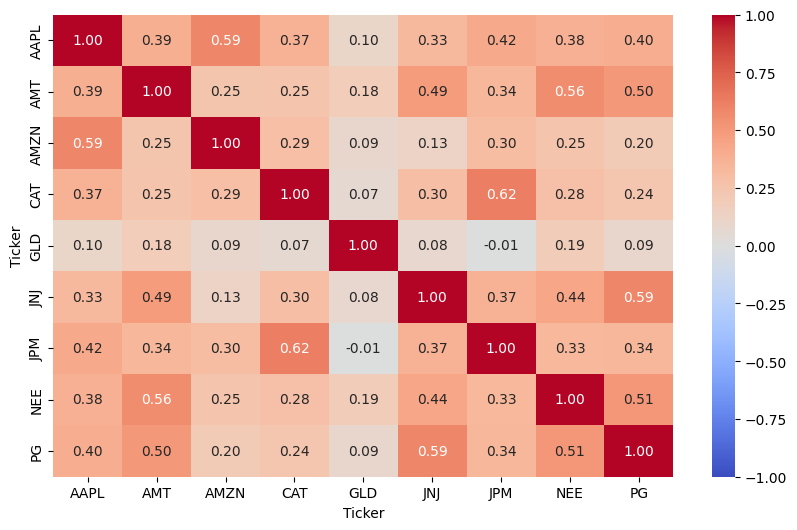

In [65]:
plt.figure(figsize=(10, 6))
sns.heatmap(data_returns.corr(), annot=True, vmin=-1, vmax=1, cmap='coolwarm', fmt=".2f")

## Historical VaR

In [81]:
hist = data * portfolio_weights
sorted_hist = hist.sum(axis=1).sort_values(ascending=False)


# Simulation Monte Carlo

In [50]:
def simulation_gbm (weights, returns, cov, S0 = 1.0, n_days = 252, n_sim = 10000) : 
    np.random.seed (42)
    dt = 1/n_days
    
    returns = np.asarray (returns)
    port_values = np.zeros ((n_sim, n_days+1))
    port_values [:,0] = S0

    z = np.random.normal (size=(n_sim, n_days, len(weights))) #Composant aléatoire pour la simulation
        
    for t in range (1, n_days + 1) : 
        asset_returns = (returns - 0.5 * np.diag(cov)) * dt + np.sqrt (np.diag(cov)) * np.sqrt (dt) * z [:, t-1, :]
        port_return = asset_returns @ weights
        port_values [:,t] = port_values [:, t-1] * np.exp (port_return)

    return port_values

In [51]:
simulated_portfolio_values = simulation_gbm (portfolio_weights, assets_returns, data_returns.cov(), n_days = 15)
print (simulated_portfolio_values)

[[1.         1.00222707 1.00013979 ... 0.99364448 0.99472879 0.99247695]
 [1.         1.00030859 0.99919986 ... 1.00650162 1.00726462 1.00375711]
 [1.         1.00136324 1.00235136 ... 1.00648151 1.00781651 1.00658695]
 ...
 [1.         0.99889693 0.99847059 ... 0.98787903 0.98571485 0.98642154]
 [1.         1.00177441 1.00181783 ... 1.00638401 1.00743464 1.00420594]
 [1.         0.99822425 0.99966658 ... 1.00295472 1.00369176 1.00246745]]


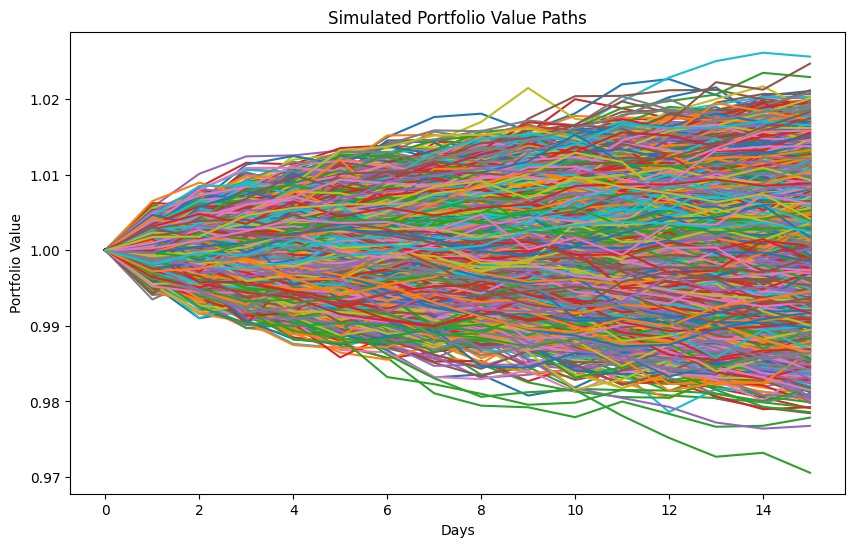

In [52]:
plt.figure(figsize=(10, 6))
t = np.linspace (0, 15, 16)

for i in range(simulated_portfolio_values.shape[0]):
    plt.plot(t, simulated_portfolio_values[i])
plt.title('Simulated Portfolio Value Paths')
plt.xlabel('Days')
plt.ylabel('Portfolio Value')
plt.show()

# Calcul VaR et CVaR

In [54]:
loss = simulated_portfolio_values[:,-1] - simulated_portfolio_values[:,0]
var_95 = np.percentile(loss, 5)
var_99 = np.percentile(loss, 1)
cvar_95 = np.mean(loss[loss <= var_95])
cvar_99 = np.mean(loss[loss <= var_99])

print (f"Value at Risk (VaR) at 95% confidence level: {var_95:.4f}")
print (f"Value at Risk (VaR) at 99% confidence level: {var_99:.4f}")
print (f"Conditional Value at Risk (CVaR) at 95% confidence level: {cvar_95:.4f}")
print (f"Conditional Value at Risk (CVaR) at 99% confidence level: {cvar_99:.4f}")


Value at Risk (VaR) at 95% confidence level: -0.0107
Value at Risk (VaR) at 99% confidence level: -0.0148
Conditional Value at Risk (CVaR) at 95% confidence level: -0.0133
Conditional Value at Risk (CVaR) at 99% confidence level: -0.0173


Interprétation : 
Sur une période de 15 jours, nous avons 95% de chance de ne pas perdre plus de 0.0107. Sur la même période, pour les 5% des pires scénarios, les pertes moyennes seraient de 0.0133. 
Sur une période de 15 jours, nous sommes sûrs à 99% de ne pas perdre plus de 0.0148. Sur la même période, les 1% des pires scénarios donneraient en moyenne une perte de 0.0173.
